# Predicting Wine Cultivar from Chemical Measurements

**Goal:** classify a wine into one of three cultivars (Class 1, 2, 3) using 13 physicochemical measurements.
This is a multi-class classification problem.

**Dataset:** [UCI Wine dataset](https://archive.ics.uci.edu/dataset/109/wine), 178 samples, 13 numeric features, no missing values.

**Workflow** (data science life cycle): understand the problem, retrieve data, prepare and explore data, train models, evaluate.

## 1. Setup and data retrieval

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# load_wine ships with scikit-learn, so no download is needed
wine = load_wine(as_frame=True)
df = wine.frame.rename(columns={"target": "cultivar"})
df["cultivar"] = df["cultivar"] + 1   # classes 0-2 -> 1-3, matching the UCI labels
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1


## 2. Data preparation and exploration

In [2]:
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print()
print("Class balance:")
print(df["cultivar"].value_counts().sort_index())

Shape: (178, 14)
Missing values: 0

Class balance:
cultivar
1    59
2    71
3    48
Name: count, dtype: int64


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


The classes are reasonably balanced (59 / 71 / 48), so accuracy is a fair metric here.
The features are on very different scales (proline is in the hundreds, hue is around 1), so scale-sensitive models will need standardization.

### Correlation between features

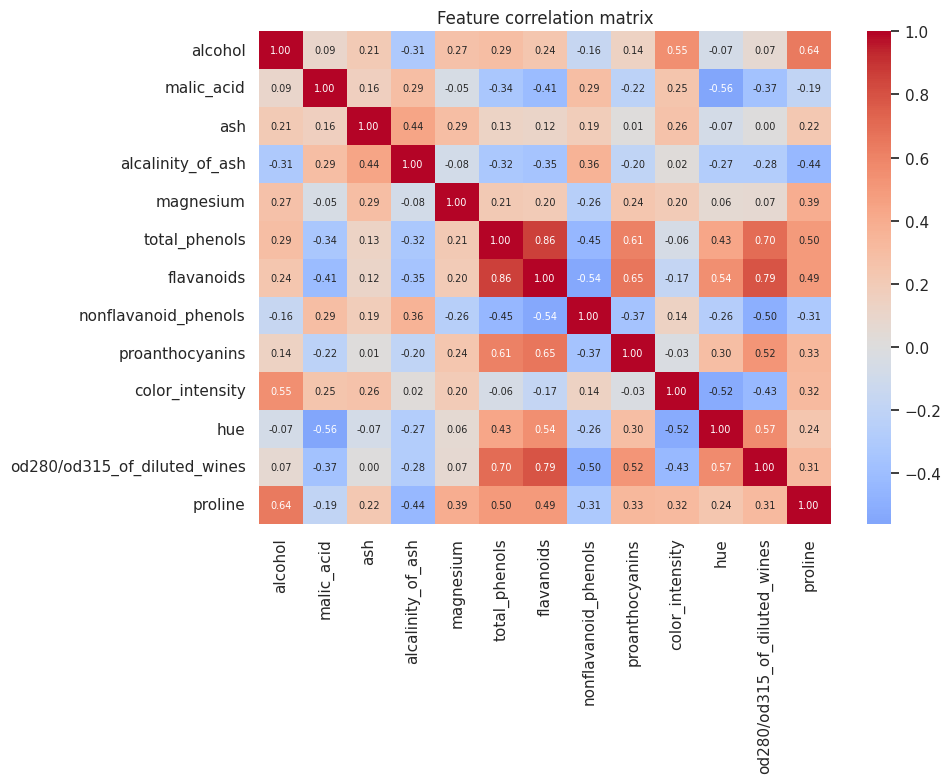

In [4]:
features = [c for c in df.columns if c != "cultivar"]
corr = df[features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

In [5]:
# Most strongly correlated feature pairs
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack()
             .sort_values(key=abs, ascending=False))
pairs.head(5).round(3)

total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
total_phenols  od280/od315_of_diluted_wines    0.700
flavanoids     proanthocyanins                 0.653
alcohol        proline                         0.644
dtype: float64

`flavanoids` and `total_phenols` are strongly correlated (about 0.86), and `flavanoids` / `od280/od315` are close behind (about 0.79).
No pair is a near-duplicate, so I keep all 13 features. Regularized and tree-based models handle moderate correlation well.

### How do the cultivars separate?

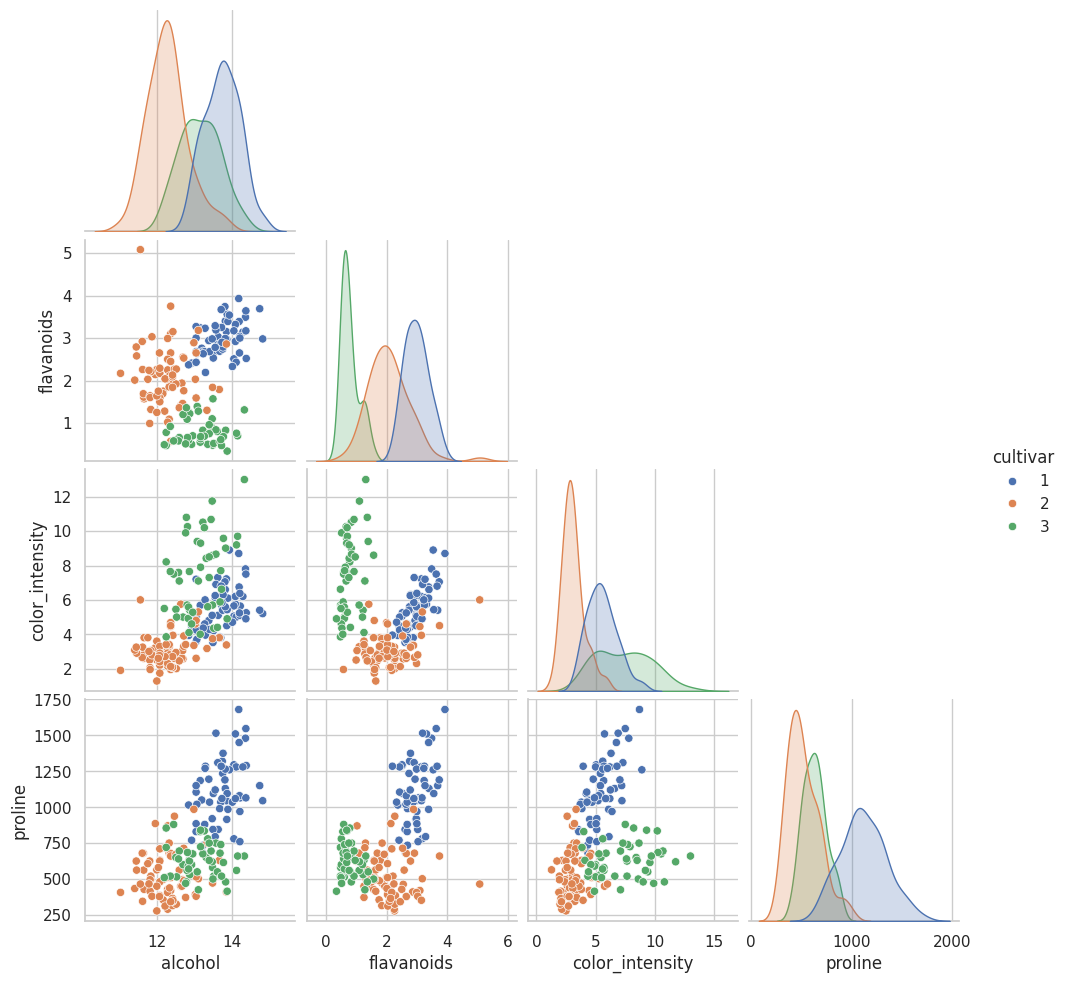

In [6]:
cols = ["alcohol", "flavanoids", "color_intensity", "proline", "cultivar"]
sns.pairplot(df[cols], hue="cultivar", palette="deep", corner=True)
plt.show()

Flavanoids, color intensity and proline each separate at least one cultivar clearly, which suggests the classes should be quite learnable from these measurements.

## 3. Train / test split

The UCI file is **sorted by class**. A sequential split (for example, "last 50 rows as the test set") would put almost only Class 3 in the test set, so I use a shuffled, **stratified** split that keeps class proportions the same in both sets.

In [7]:
X = df[features]
y = df["cultivar"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Train class share:", y_train.value_counts(normalize=True).sort_index().round(2).to_dict())
print("Test class share: ", y_test.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (133, 13)  Test: (45, 13)

Train class share: {1: 0.33, 2: 0.4, 3: 0.27}
Test class share:  {1: 0.33, 2: 0.4, 3: 0.27}


## 4. Select and train models

Two models, compared with 5-fold stratified cross-validation on the training set only (the test set stays untouched until the end):

- **Logistic regression** with standardized features: a simple, interpretable baseline.
- **Random forest**: a non-linear model that does not need scaling.

In [8]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"model": name, "cv_mean_accuracy": scores.mean(), "cv_std": scores.std()})

pd.DataFrame(rows).round(3)

,model,cv_mean_accuracy,cv_std
0,Logistic regression,0.977,0.018
1,Random forest,0.985,0.030


## 5. Evaluate on the held-out test set

In [9]:
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = model.predict(X_test)
    print(f"{name}: test accuracy = {accuracy_score(y_test, results[name]):.3f}")

Logistic regression: test accuracy = 1.000


Random forest: test accuracy = 1.000


Detailed report for: Logistic regression

              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        15
     Class 2       1.00      1.00      1.00        18
     Class 3       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



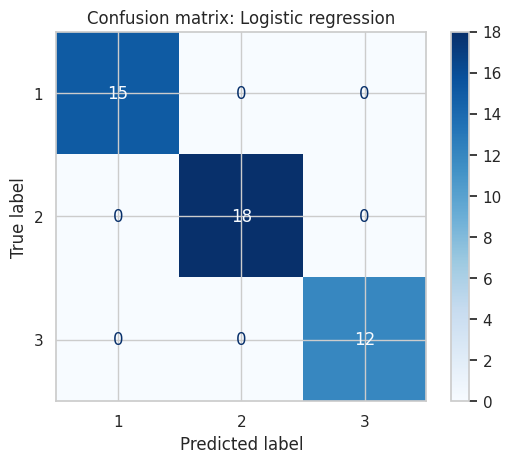

In [10]:
best_name = max(results, key=lambda n: accuracy_score(y_test, results[n]))
print("Detailed report for:", best_name)
print()
print(classification_report(y_test, results[best_name], target_names=["Class 1", "Class 2", "Class 3"]))

ConfusionMatrixDisplay.from_predictions(y_test, results[best_name], cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

### Which features matter most?

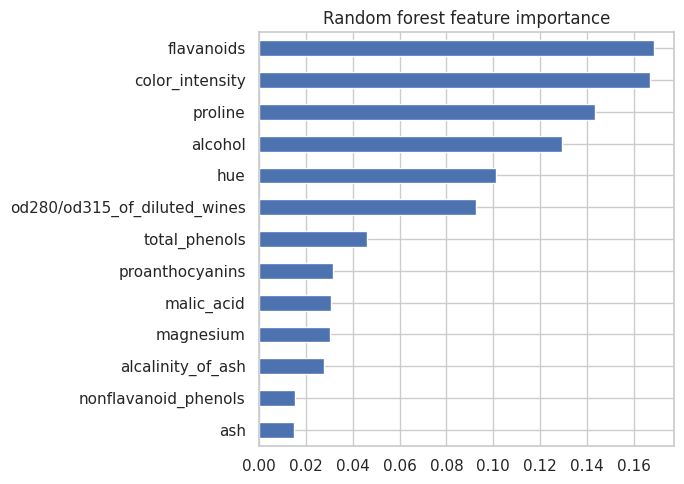

In [11]:
rf = models["Random forest"]
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind="barh", figsize=(7, 5), title="Random forest feature importance")
plt.tight_layout()
plt.show()

## 6. Lessons from my first attempt

My original version of this project had two problems, and both are worth recording:

1. **Wrong problem framing.** I set `Alcohol` as the target and used linear regression, which does not match the stated goal of predicting the cultivar. The target should be `Class`, with a classification model.
2. **Sequential split on sorted data.** The test set (last 50 rows) held almost only Class 3 wines, which the model had barely seen in training. That is why the R² came out at about -4.45, meaning it did worse than predicting the mean. A shuffled, stratified split fixes the evaluation problem.

## 7. Conclusion

Following the data science life cycle (understand the problem, retrieve data, prepare and explore, train, evaluate) produced a reproducible pipeline.
Both models classify the cultivar very accurately from the 13 chemical measurements: about 98% cross-validated accuracy for each (random forest 98.5%, logistic regression 97.7%, a difference within noise) and 100% on the held-out test set.
Because the two models perform about equally, the simpler and more interpretable logistic regression would be my pick.

**Caveats:** the dataset is small (178 rows), so the test set is only 45 wines and a single misclassification moves accuracy by about 2 percentage points, so 100% test accuracy should not be read as a guarantee of perfect performance on new data. The cross-validation scores (about 98%) are a more stable estimate.
Fine-tuning and deployment were out of scope for this project.

**References**
1. UCI Machine Learning Repository, Wine dataset: https://archive.ics.uci.edu/dataset/109/wine
2. scikit-learn documentation: https://scikit-learn.org/stable/